In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

In [13]:
housing = fetch_california_housing()
data = pd.DataFrame(housing.data,columns=housing.feature_names)
data["Price"] = housing.target

In [17]:
#select one feature
X = data[['AveRooms']].values
Y = data['Price'].values

In [55]:
#split data
X_train,X_test,Y_train,Y_test = train_test_split(
    X, Y,
    test_size = 0.2,
    random_state = 50,
)

In [56]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [57]:
w = 0
b = 0
learning_rate = 0.01
epochs = 1000
cost_history = []
n = len(X_train_scaled)
for i in range(epochs):
    Y_pred = w * X_train_scaled.flatten() + b
    cost = (1/(2*n)) * np.sum((Y_pred - Y_train)**2)
    cost_history.append(cost)
    dw = (1/n)*np.sum((Y_pred - Y_train) * X_train_scaled.flatten())
    db = (1/n)*np.sum(Y_pred - Y_train)
    w = w - learning_rate * dw
    b = b - learning_rate * db
    if i % 100 ==0:
        
        print(f"Epoch {i},Cost = {cost:.4f}")
Y_pred_gd = w * X_test_scaled.flatten() + b
    

Epoch 0,Cost = 2.8044
Epoch 100,Cost = 0.9425
Epoch 200,Cost = 0.6930
Epoch 300,Cost = 0.6596
Epoch 400,Cost = 0.6551
Epoch 500,Cost = 0.6545
Epoch 600,Cost = 0.6545
Epoch 700,Cost = 0.6544
Epoch 800,Cost = 0.6544
Epoch 900,Cost = 0.6544


In [58]:
print("Gradient Descent")
print("---------------")
print("Weight:", w)
print("Bias:",b)
print("MSE:",mean_squared_error(Y_test, Y_pred_gd))
print("R2 Score :",r2_score(Y_test, Y_pred_gd))

Gradient Descent
---------------
Weight: 0.1753167020173614
Bias: 2.0661167598248436
MSE: 1.2685994646608647
R2 Score : 0.023481096671401303


In [59]:
X_train_ne = np.c_[np.ones((len(X_train),1)), X_train]
X_test_ne = np.c_[np.ones((len(X_test),1)), X_test]
theta = np.linalg.inv(X_train_ne.T @ X_train_ne) @X_train_ne.T @ Y_train
Y_pred_ne = X_test_ne @ theta

In [60]:
print("Normal Equation")
print("---------------")
print("Intercept:", theta[0])
print("slope:",theta[1])
print("MSE:",mean_squared_error(Y_test, Y_pred_gd))
print("R2 Score :",r2_score(Y_test, Y_pred_gd))

Normal Equation
---------------
Intercept: 1.6918192154378002
slope: 0.06894062439366382
MSE: 1.2685994646608647
R2 Score : 0.023481096671401303


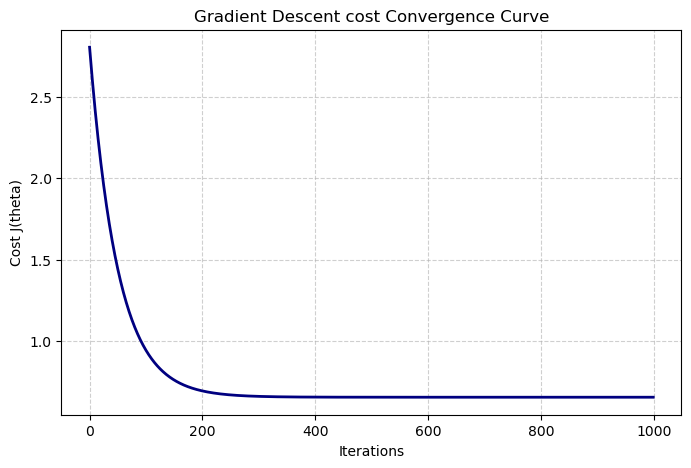

In [62]:
plt.figure(figsize=(8,5))
plt.plot(cost_history, color='navy', linewidth=2)
plt.title('Gradient Descent cost Convergence Curve')
plt.xlabel('Iterations')
plt.ylabel('Cost J(theta)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


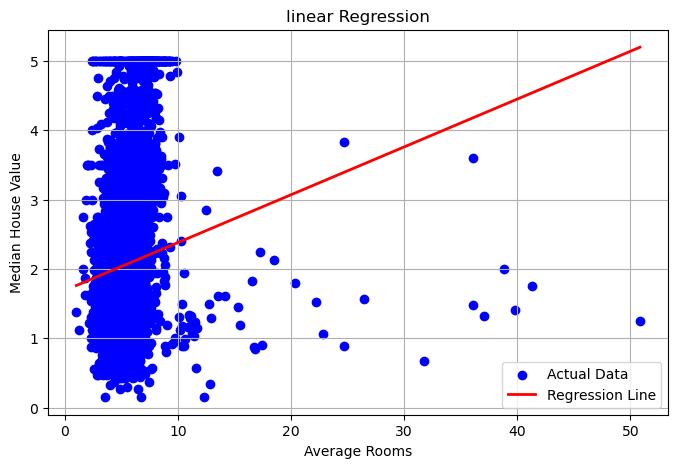

In [63]:
index = np.argsort(X_test.flatten())
plt.figure(figsize=(8, 5))
plt.scatter(X_test, Y_test, color='blue', label='Actual Data')
#regression line
plt.plot(
    X_test.flatten()[index],
    Y_pred_ne[index],
    color='red',
    linewidth=2,
    label='Regression Line'
)
plt.title("linear Regression")
plt.xlabel("Average Rooms")
plt.ylabel("Median House Value")
plt.legend()
plt.grid(True)
plt.show()